In [14]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
# ============================================================
# 2. LOAD AND CHECK DATA
# ============================================================
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/heart.csv')

print("Original dataset shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum())

df = df.drop_duplicates().copy()

Original dataset shape: (303, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  

Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


(302, 14)
          count        mean        std    min     25%    50%     75%    max
age       302.0   54.420530   9.047970   29.0   48.00   55.5   61.00   77.0
sex       302.0    0.682119   0.466426    0.0    0.00    1.0    1.00    1.0
cp        302.0    0.963576   1.032044    0.0    0.00    1.0    2.00    3.0
trestbps  302.0  131.602649  17.563394   94.0  120.00  130.0  140.00  200.0
chol      302.0  246.500000  51.753489  126.0  211.00  240.5  274.75  564.0
fbs       302.0    0.149007   0.356686    0.0    0.00    0.0    0.00    1.0
restecg   302.0    0.526490   0.526027    0.0    0.00    1.0    1.00    2.0
thalach   302.0  149.569536  22.903527   71.0  133.25  152.5  166.00  202.0
exang     302.0    0.327815   0.470196    0.0    0.00    0.0    1.00    1.0
oldpeak   302.0    1.043046   1.161452    0.0    0.00    0.8    1.60    6.2
slope     302.0    1.397351   0.616274    0.0    1.00    1.0    2.00    2.0
ca        302.0    0.718543   1.006748    0.0    0.00    0.0    1.00    4.0
th

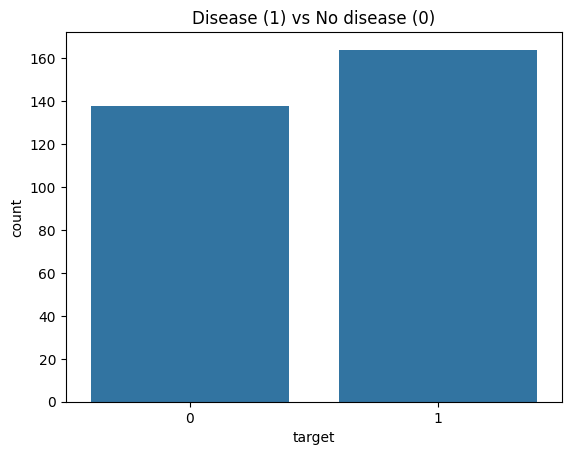

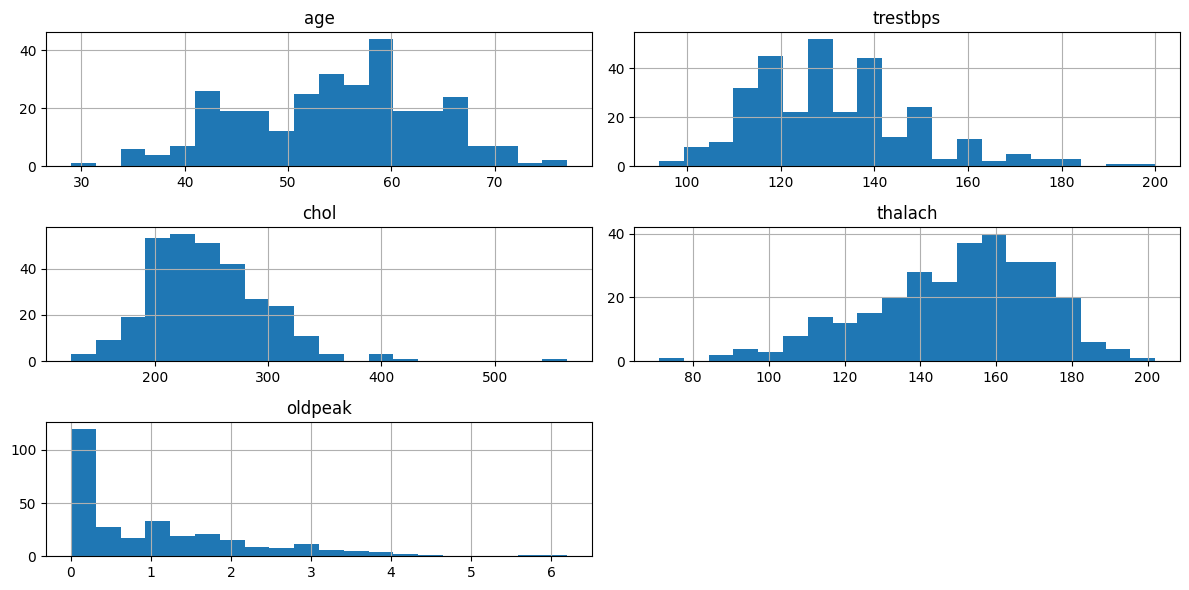

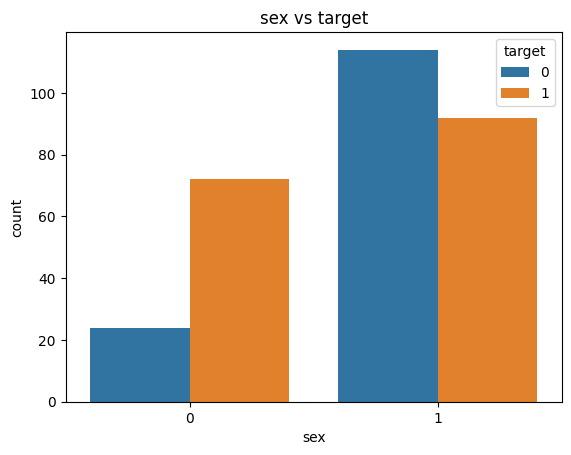

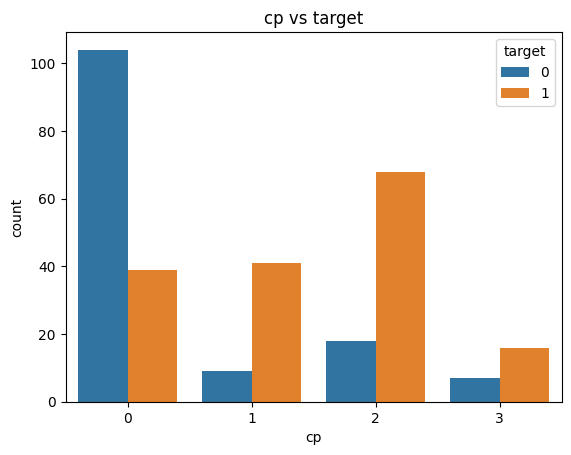

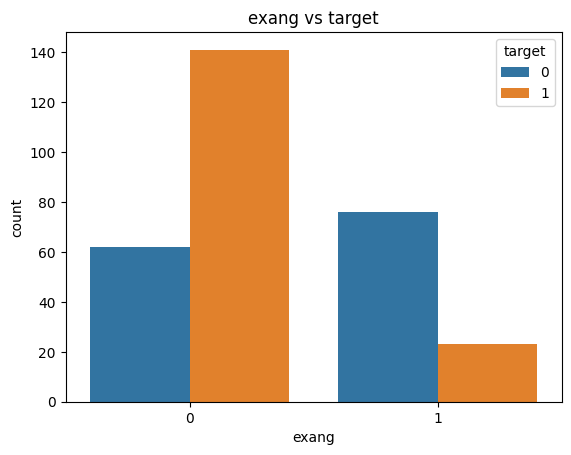

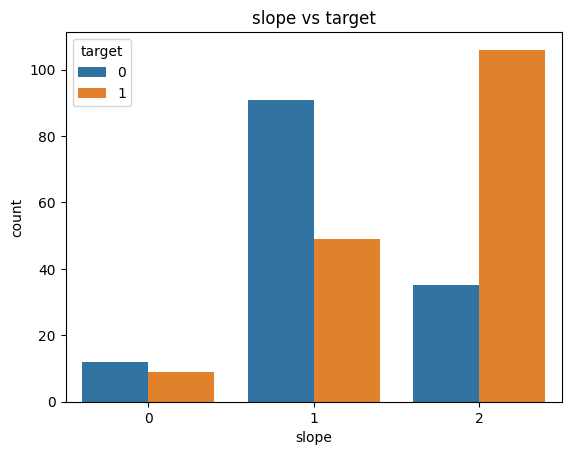

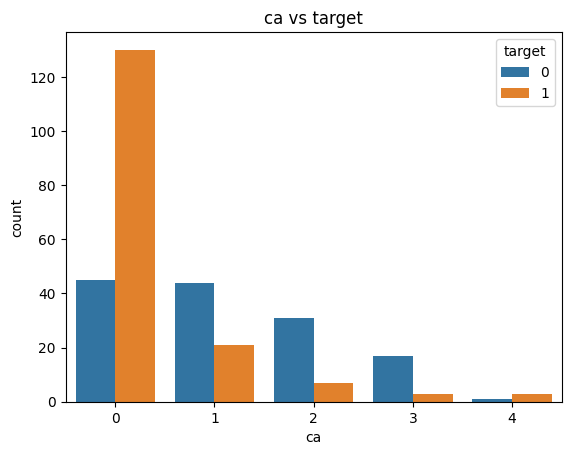

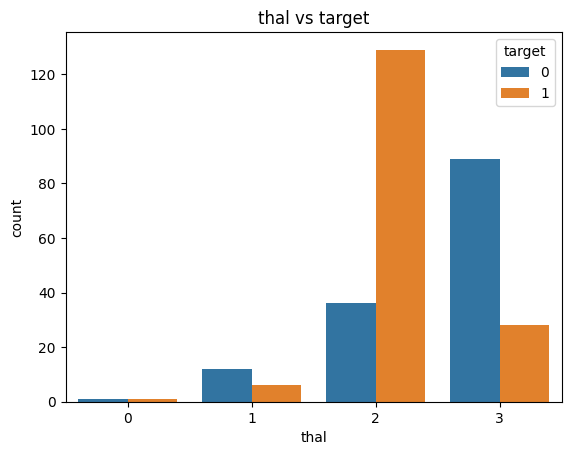

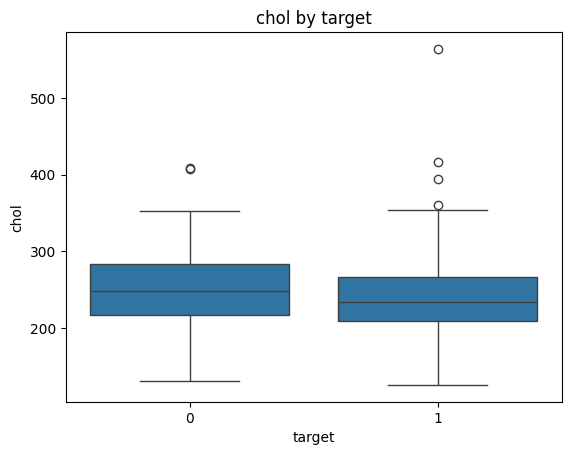

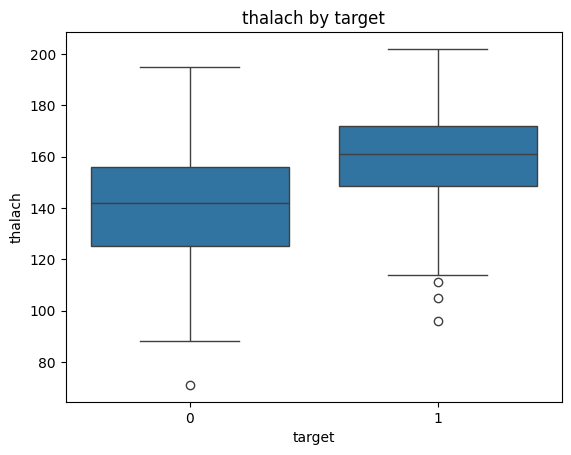

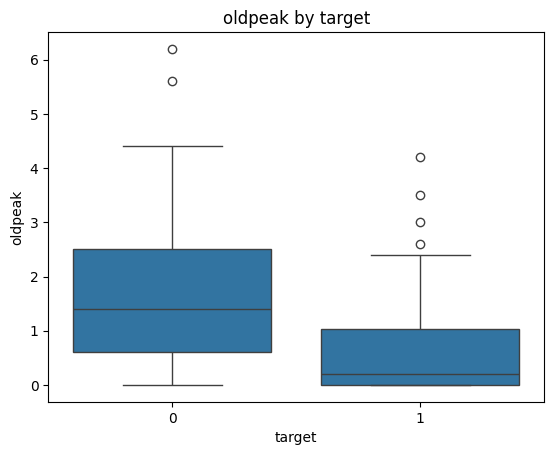

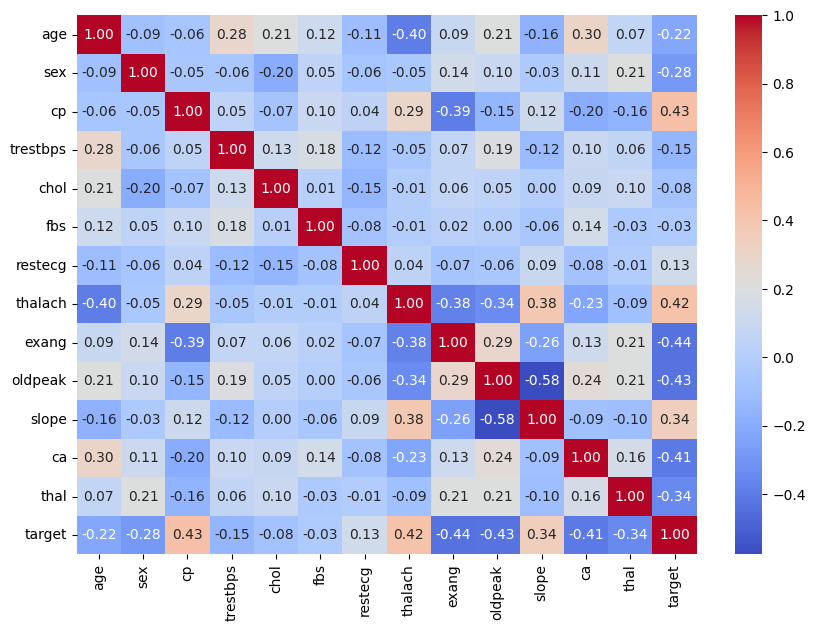

In [17]:
# ---------- EDA ----------
print(df.shape)
print(df.describe().T)

# 1. Class balance
sns.countplot(x='target', data=df)
plt.title('Disease (1) vs No disease (0)'); plt.show()

# 2. Distribution of numeric features
df[['age','trestbps','chol','thalach','oldpeak']].hist(bins=20, figsize=(12,6))
plt.tight_layout(); plt.show()

# 3. Categorical features vs target
for col in ['sex','cp','exang','slope','ca','thal']:
    sns.countplot(x=col, hue='target', data=df)
    plt.title(f'{col} vs target'); plt.show()

# 4. Outliers: boxplots by target
for col in ['chol','thalach','oldpeak']:
    sns.boxplot(x='target', y=col, data=df)
    plt.title(f'{col} by target'); plt.show()

# 5. Correlation heatmap
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [18]:
# Automatically identify a common target-column name.
possible_targets = [
    "target", "HeartDisease", "heart_disease_status",
    "output", "condition", "HeartDiseaseStatus"
]

target_col = next(
    (col for col in possible_targets if col in df.columns),
    None
)

if target_col is None:
    raise ValueError(
        "Target column not detected. Set target_col manually "
        "to the column representing heart disease."
    )

print("\nTarget column:", target_col)
print("Dataset shape after removing duplicates:", df.shape)

# Remove rows with missing target labels
df = df.dropna(subset=[target_col]).copy()

X = df.drop(columns=[target_col])
y = df[target_col]

# Encode categorical target labels, if needed
if y.dtype == "object" or str(y.dtype) == "category":
    y = LabelEncoder().fit_transform(y.astype(str).str.strip())

if pd.Series(y).nunique() != 2:
    raise ValueError("This code expects a binary heart disease target.")

print("\nTarget distribution:\n", pd.Series(y).value_counts())


Target column: target
Dataset shape after removing duplicates: (302, 14)

Target distribution:
 target
1    164
0    138
Name: count, dtype: int64


In [19]:
# ============================================================
# 3. TRAIN-TEST SPLIT
# ============================================================
# Keep the test set separate from model selection.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()


In [20]:
# ============================================================
# 4. PREPROCESSING
# ============================================================
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


In [21]:
# ============================================================
# 5. DEFINE MODELS AND HYPERPARAMETERS
# ============================================================
models = {
    "Logistic Regression": (
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ),
        {
            "model__C": [0.01, 0.1, 1, 10, 100]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        {
            "model__n_estimators": [200, 400],
            "model__max_depth": [None, 4, 8],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.8]
        }
    ),

    "Extra Trees": (
        ExtraTreesClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        {
            "model__n_estimators": [200, 400],
            "model__max_depth": [None, 4, 8],
            "model__min_samples_leaf": [1, 2, 4]
        }
    ),

    "Support Vector Machine": (
        SVC(
            probability=True,
            class_weight="balanced",
            random_state=42
        ),
        {
            "model__C": [0.1, 1, 10],
            "model__kernel": ["linear", "rbf"]
        }
    ),

    "K-Nearest Neighbors": (
        KNeighborsClassifier(),
        {
            "model__n_neighbors": [3, 5, 7, 9, 11],
            "model__weights": ["uniform", "distance"]
        }
    )
}

In [22]:
# ============================================================
# 6. CROSS-VALIDATION AND HYPERPARAMETER TUNING
# ============================================================
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_models = {}
cv_results = []

for name, (estimator, param_grid) in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", estimator)
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    cv_results.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print(f"\n{name}")
    print("Best cross-validation F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)


Logistic Regression
Best cross-validation F1: 0.8417
Best parameters: {'model__C': 0.01}

Random Forest
Best cross-validation F1: 0.861
Best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__n_estimators': 400}

Extra Trees
Best cross-validation F1: 0.8598
Best parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}

Support Vector Machine
Best cross-validation F1: 0.8551
Best parameters: {'model__C': 1, 'model__kernel': 'linear'}

K-Nearest Neighbors
Best cross-validation F1: 0.8277
Best parameters: {'model__n_neighbors': 7, 'model__weights': 'uniform'}


In [23]:
# ============================================================
# 7. COMPARE MODELS ON THE HELD-OUT TEST SET
# ============================================================
results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

print("\nFINAL TEST-SET COMPARISON")
print(results_df.round(4).to_string(index=False))

print("\nCROSS-VALIDATION COMPARISON")
cv_df = pd.DataFrame(cv_results).sort_values(
    by="Best CV F1", ascending=False
)
print(cv_df[["Model", "Best CV F1"]].round(4).to_string(index=False))


FINAL TEST-SET COMPARISON
                 Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
         Random Forest    0.8197     0.7750  0.9394    0.8493   0.9015
   K-Nearest Neighbors    0.8197     0.7895  0.9091    0.8451   0.8912
           Extra Trees    0.8033     0.7692  0.9091    0.8333   0.9102
   Logistic Regression    0.7869     0.7500  0.9091    0.8219   0.8864
Support Vector Machine    0.7705     0.7436  0.8788    0.8056   0.8820

CROSS-VALIDATION COMPARISON
                 Model  Best CV F1
         Random Forest      0.8610
           Extra Trees      0.8598
Support Vector Machine      0.8551
   Logistic Regression      0.8417
   K-Nearest Neighbors      0.8277



Selected model: Random Forest

Classification report:

              precision    recall  f1-score   support

           0       0.90      0.68      0.78        28
           1       0.78      0.94      0.85        33

    accuracy                           0.82        61
   macro avg       0.84      0.81      0.81        61
weighted avg       0.83      0.82      0.82        61

ROC AUC: 0.9015


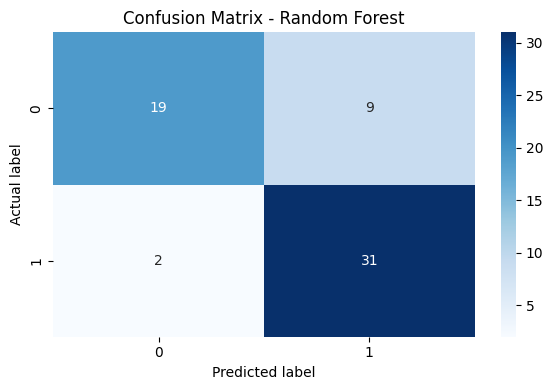

In [24]:
# ============================================================
# 8. EVALUATE THE SELECTED MODEL
# ============================================================
best_name = results_df.iloc[0]["Model"]
best_model = best_models[best_name]

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("\nSelected model:", best_name)
print("\nClassification report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

print("ROC AUC:", round(roc_auc_score(y_test, y_prob), 4))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

In [25]:
results_df.to_csv(
    "/content/drive/MyDrive/Colab Notebooks/heart_model_comparison.csv",
    index=False
)

print("Results saved to Google Drive!")

Results saved to Google Drive!
